In [198]:
import math
import timeit
from abc import ABC,abstractmethod
import numpy as np
import matplotlib.pyplot as plt


STRUCTURE ALGEBRIQUE D'UN POLYNOME

In [199]:
# Classe abstraite pour les structures algébriques (facultative mais pédagogique)
from polynome import Polynome
class StructureAlgebrique(ABC):
    @abstractmethod
    def __add__(self, other):
        pass
    @abstractmethod
    def __mul__(self, other):
        pass
    @property
    @abstractmethod
    def zero(self):
        pass
    @abstractmethod
    def __eq__(self, other):
        pass
    def __ne__(self, other):
        return not self.__eq__(other)
        
      
    # --- Opérations arithmétiques ---
    def __add__(self, other):
        if not isinstance(other, Polynome):
            other = Polynome([other])
        n = max(len(self), len(other))
        resultat = [self[i] + other[i] for i in range(n)]
        return Polynome(resultat)

    def __neg__(self):
        return Polynome([-c for c in self.coeffs])

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        if isinstance(other, (int, float)):
            return Polynome([c * other for c in self.coeffs])
        if not isinstance(other, Polynome):
            other = Polynome([other])
        if self.degre == -1 or other.degre == -1:
            return Polynome([0])
        resultat = [0] * (self.degre + other.degre + 1)
        for i, ai in enumerate(self.coeffs):
            for j, bj in enumerate(other.coeffs):
                resultat[i + j] += ai * bj
        return Polynome(resultat)

    def __rmul__(self, scalaire):
        return self.__mul__(scalaire)

    def __pow__(self, n):
        if n == 0:
            return Polynome([1])
        if n % 2 == 0:
            demi = self ** (n // 2)
            return demi * demi
        return self * (self ** (n - 1))

   

CLASS D'UN POLYNOME

In [200]:
class Polynome(StructureAlgebrique):
    """Classe représentant un polynôme à coefficients réels."""

    def __init__(self, coeffs):
        # coeffs : liste [a0, a1, ..., an] pour a0 + a1*X + ... + an*X^n
        self.coeffs = list(coeffs)
        self._normaliser()

    def _normaliser(self):
        """Supprime les zéros en tête (coefficients dominants nuls)."""
        while len(self.coeffs) > 1 and self.coeffs[-1] == 0:
            self.coeffs.pop()
        if self.coeffs == []:
            self.coeffs = [0]

    @property
    def degre(self):
        """Retourne le degré du polynôme ( -1 pour le polynôme nul)."""
        if self.coeffs == [0]:
            return -1
        return len(self.coeffs) - 1

    @property
    def zero(self):
        return Polynome([0])

    # --- Accès aux coefficients ---
    def __len__(self):
        return len(self.coeffs)

    def __getitem__(self, i):
        if 0 <= i < len(self.coeffs):
            return self.coeffs[i]
        return 0

    # --- Égalité ---
    def __eq__(self, other):
        if isinstance(other, (int, float)):
            return self.coeffs == [other]
        if isinstance(other, Polynome):
            return self.coeffs == other.coeffs
        return False

    # --- Représentation ---
    def __repr__(self):
        return f"Polynome({self.coeffs})"

    def __str__(self):
        if self.degre == -1:
            return "0"
        termes = []
        for i, c in enumerate(self.coeffs):
            if c == 0:
                continue
            if i == 0:
                termes.append(str(c))
            elif i == 1:
                if c == 1:
                    termes.append("X")
                elif c == -1:
                    termes.append("-X")
                else:
                    termes.append(f"{c}*X")
            else:
                if c == 1:
                    termes.append(f"X^{i}")
                elif c == -1:
                    termes.append(f"-X^{i}")
                else:
                    termes.append(f"{c}*X^{i}")
        return " + ".join(reversed(termes))

        # --- Dérivée formelle ---
    def derivee(self):
        if self.degre <= 0:
            return Polynome([0])
        return Polynome([i * self.coeffs[i] for i in range(1, len(self.coeffs))])

    # --- Intégrale (primitive avec constante c) ---
    def integrer(self, c=0):
        # primitive : constante c + Σ a_i * X^{i+1}/(i+1)
        new_coeffs = [c] + [self.coeffs[i] / (i + 1) for i in range(len(self.coeffs))]
        return Polynome(new_coeffs)

    # --- Division euclidienne ---
    def division_euclidienne(self, diviseur):
        if diviseur == Polynome([0]):
            raise ZeroDivisionError("Division par le polynôme nul")
        dividende = Polynome(self.coeffs[:])
        quotient = Polynome([0])
        while dividende.degre >= diviseur.degre and dividende.degre != -1:
            deg_diff = dividende.degre - diviseur.degre
            coeff_div = dividende.coeffs[-1] / diviseur.coeffs[-1]
            monome_coeffs = [0] * deg_diff + [coeff_div]
            monome = Polynome(monome_coeffs)
            quotient = quotient + monome
            dividende = dividende - (monome * diviseur)
        return quotient, dividende

    # --- PGCD (méthode statique) ---
    @staticmethod
    def pgcd(A, B):
        while B != Polynome([0]):
            _, R = A.division_euclidienne(B)
            A, B = B, R
        # Normalisation
        lc = A.coeffs[-1]
        return Polynome([c / lc for c in A.coeffs])

    # --- Méthode __call__ pour évaluation directe ---
    def __call__(self, x):
        return self.evaluer(x)
 # --- Évaluation par Horner ---
    def evaluer(self, x):
        res = 0
        for coeff in reversed(self.coeffs):
            res = res * x + coeff
        return res

    
        
        # Création de polynômes
P = Polynome([-5, 1, -2, 3])   # 3X^3 -2X^2 + X -5
G = Polynome([3, 1, 2])        # 2X^2 + X + 3

print(f"P = {P}")
print(f"G = {G}")
print(f"P + G = {P + G}")
print(f"P évalué en 4 : {P.evaluer(8)}")
print(f"Dérivée de P : {P.derivee()}")
print(f"Intégrale de P (constante 0) : {P.integrer()}")
print(f"Degré de P : {P.degre}")

# PGCD
A = Polynome([-1, 0, 0, 1])   # X^3 - 1
B = Polynome([-1, 0, 1])      # X^2 - 1
print(f"PGCD({A}, {B}) = {Polynome.pgcd(A, B)}")   # attendu X - 1




P = 3*X^3 + -2*X^2 + X + -5
G = 2*X^2 + X + 3
P + G = 3*X^3 + 2*X + -2
P évalué en 4 : 1411
Dérivée de P : 9*X^2 + -4*X + 1
Intégrale de P (constante 0) : 0.75*X^4 + -0.6666666666666666*X^3 + 0.5*X^2 + -5.0*X
Degré de P : 3
PGCD(X^3 + -1, X^2 + -1) = X + -1.0


TESTS SUR LES OPERATIONS DES POLYNOMES

In [201]:
#Test
P=Polynome([-3,1,-8,3])
print(f"Le polynome P s'écrit {P}")
G=Polynome([7,2,3])
print(f"Le polynome G s'écrit {G}")
print(f"La somme de P et G est {P+G}")
print(f"P évalué en 4 :{P.evaluer(8)} ")
print(f"La dérivée de P est : {P.derivee()}")
print(f"le degré de P est :{P.degre}")
print(f"Le pgcd de P par G est :{Polynome.pgcd(P,G)}")
print(f"L'intégrale de P  est {P.integrer()}")
print(f"L'intégrale de G  est {G.integrer()}")

Le polynome P s'écrit 3*X^3 + -8*X^2 + X + -3
Le polynome G s'écrit 3*X^2 + 2*X + 7
La somme de P et G est 3*X^3 + -5*X^2 + 3*X + 4
P évalué en 4 :1029 
La dérivée de P est : 9*X^2 + -16*X + 1
le degré de P est :3
Le pgcd de P par G est :1.0
L'intégrale de P  est 0.75*X^4 + -2.6666666666666665*X^3 + 0.5*X^2 + -3.0*X
L'intégrale de G  est X^3 + X^2 + 7.0*X


In [202]:
A = Polynome([-1, 0, 0, 1])   # X^3 - 1
B = Polynome([-1, 0, 1])       # X^2 - 1
G = Polynome.pgcd(A, B)
print(f"pgcd(X^3-1, X^2-1) = {G}")  # attendu : X - 1
Q, R = A.division_euclidienne(B)
print(f"Vérification : B*Q + R = {B*Q + R}")  # doit égaler A

pgcd(X^3-1, X^2-1) = X + -1.0
Vérification : B*Q + R = X^3 + -1


CLASSE MATRICE 

In [203]:
class Matrice:
    """
    Matrice m×n de réels, stockée en liste de listes (lignes).
    """

    def __init__(self,data):
        self.data = data
        self.m = len(self.data)
        self.n = len(self.data[0]) if self.data else 0

    @classmethod
    def nulle(cls, m, n):
        """Matrice nulle m×n."""
        return cls([[0.0] * n for _ in range(m)])
        

    @classmethod
    def identite(cls, n):
        """Matrice identité n×n."""
        M = cls.nulle(n, n)
        for i in range(n):
            M.data[i][i] = 1.0
        return M

    @classmethod
    def aleatoire(cls, m, n, entiers=False, borne=10):
        """Matrice aléatoire m×n."""
        if entiers:
            return cls([[random.randint(-borne, borne) for _ in range(n)]
                        for _ in range(m)])
        return cls([[random.uniform(-borne, borne) for _ in range(n)]
                    for _ in range(m)])

    def __getitem__(self, idx):
        i, j = idx
        return self.data[i][j]

    def __setitem__(self, idx, val):
        i, j = idx
        self.data[i][j] = val

    def __repr__(self):
        return f"Matrice({self.data})"

    def __str__(self):
        larg = max(len(f"{self.data[i][j]:.3g}")
                   for i in range(self.m) for j in range(self.n))
        rows = ["  ".join(f"{x:{larg}.3g}" for x in ligne)
                for ligne in self.data]
        return "\n".join(f"| {r} |" for r in rows)

      # --- Opérations ---
    def __add__(self, other):
        assert self.m == other.m and self.n == other.n, "Dimensions incompatibles"
        return Matrice([[self.data[i][j] + other.data[i][j] for j in range(self.n)] for i in range(self.m)])

    def __neg__(self):
        return Matrice([[-x for x in ligne] for ligne in self.data])

    def __sub__(self, other):
        return self + (-other)

    def __mul__(self, other):
        """n=len(self.data)
        m=len(other.data[0])
        p=len(self.data[0])
        resultat=[[0]*m for _ in range (n)]
        for i in range (n):
            for j in range (m):
                s=0
                for k in range (p):
                    s += self.data[i][k] * other.data[k][j]
                resultat.data[i][j] = s

        return Matrice(resultat)"""
        if isinstance(other, (int, float)):
            return Matrice([[other * x for x in ligne] for ligne in self.data])
        assert self.n == other.m, "Dimensions incompatibles pour multiplication"
        resultat = Matrice.nulle(self.m, other.n)
        for i in range(self.m):
            for j in range(other.n):
                s = 0
                for k in range(self.n):
                    s += self.data[i][k] * other.data[k][j]
                resultat.data[i][j] = s
        return Matrice(resultat)

    def transpose(self):
        return Matrice([[self.data[i][j] for i in range(self.m)] for j in range(self.n)])

    def trace(self):
        assert self.m == self.n, "La trace est définie pour les matrices carrées"
        return sum(self.data[i][i] for i in range(self.n))


    # --- Gauss-Jordan ---
    def gauss_jordan(self, b=None):
        import copy
        n = self.m
        if b is not None:
            M = [row[:] + [b[i]] for i, row in enumerate(self.data)]
            ncols = n + 1
        else:
            M = [row[:] for row in self.data]
            ncols = self.n
    
        pivot_col = 0
        for pivot_row in range(n):
            # pivot partiel
            if pivot_col >= ncols:
                break
            max_val = abs(M[pivot_row][pivot_col])
            max_row = pivot_row
            for k in range(pivot_row + 1, n):
                if abs(M[k][pivot_col]) > max_val:
                    max_val = abs(M[k][pivot_col])
                    max_row = k
            if max_val < 1e-12:
                pivot_col += 1
                continue
            M[pivot_row], M[max_row] = M[max_row], M[pivot_row]
            pivot = M[pivot_row][pivot_col]
            M[pivot_row] = [x / pivot for x in M[pivot_row]]
            for i in range(n):
                if i != pivot_row and abs(M[i][pivot_col]) > 1e-12:
                    facteur = M[i][pivot_col]
                    M[i] = [M[i][j] - facteur * M[pivot_row][j] for j in range(ncols)]
            pivot_col += 1
    
        if b is not None:
            return [M[i][-1] for i in range(n)]
        return Matrice([row[:self.n] for row in M])

    
        # --- Déterminant par Gauss ---
    def determinant(self):
        assert self.m == self.n, "Le déterminant est défini pour les matrices carrées"
        n = self.n
        M = [row[:] for row in self.data]
        det = 1.0
        for col in range(n):
            # pivot partiel
            max_row = max(range(col, n), key=lambda r: abs(M[r][col]))
            if abs(M[max_row][col]) < 1e-12:
                return 0.0
            if max_row != col:
                M[col], M[max_row] = M[max_row], M[col]
                det *= -1
            det *= M[col][col]
            for i in range(col + 1, n):
                facteur = M[i][col] / M[col][col]
                for j in range(col, n):
                    M[i][j] -= facteur * M[col][j]
        return det
        

# Exemple
A = Matrice([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
print(A)
print(f"\nDimensions : {A.m} x {A.n}")

| 1  2  3 |
| 4  5  6 |
| 7  8  9 |

Dimensions : 3 x 3


In [204]:
def matrice_add(self, other):
    """
    Addition terme à terme. Complexité : O(m*n).
    Précondition : self et other ont les mêmes dimensions.
    """
    assert self.m == other.m and self.n == other.n,"Dimesion incompatible"
    return Matrice ([[ self . data [i][j] + other . data [i][j] for j in range ( self .n)]for i in range ( self .m)])
    raise NotImplementedError

def matrice_neg(self):
    return Matrice([[-x for x in lig] for lig in self.data])

def matrice_sub(self, other):
    return self.__add__(other.__neg__())

def matrice_mul(self, other):
    """
    Multiplication matricielle naïve. Complexité : O(m * n * p).
    Précondition : self est m×n, other est n×p.

    C[i][j] = sum_{k=0}^{n-1} A[i][k] * B[k][j]
    """
    def matrice_mul(self, other):
    # Multiplication par un scalaire
        if isinstance(other, (int, float)):
            return Matrice([[other * x for x in ligne] for ligne in self.data])
        # Multiplication matricielle
        assert self.n == other.m, f"Dimensions incompatibles : ({self.m},{self.n}) x ({other.m},{other.n})"
        # Initialiser une matrice de résultats avec des zéros
        resultat_data = [[0.0] * other.n for _ in range(self.m)]
        for i in range(self.m):
            for j in range(other.n):
                s = 0.0
                for k in range(self.n):
                    s += self.data[i][k] * other.data[k][j]
                resultat_data[i][j] = s
        return Matrice(resultat_data)
    
def matrice_transposee(self):
        return Matrice([[self.data[i][j] for i in range(self.m)] for j in range(self.n)])


def matrice_trace(self):
    """Trace (matrice carrée). Complexité : O(n)."""
    assert self.m == self.n, "La trace nécessite une matrice carrée"
    return sum(self.data[i][i] for i in range(self.n))

def matrice_eq(self, other):
    if not isinstance(other, Matrice):
        return NotImplemented
    return self.data == other.data


Matrice.__add__       = matrice_add
Matrice.__neg__       = matrice_neg
Matrice.__sub__       = matrice_sub
Matrice.__mul__       = matrice_mul
Matrice.transposee    = matrice_transposee
Matrice.trace         = matrice_trace
Matrice.__eq__        = matrice_eq


GAUSS JORDAN

In [205]:
from sympy import Matrix  
A = Matrice([[2, 1, -1], [-3, -1, 2], [-2, 1, 2]])
b = [8, -11, -3]
x = A.gauss_jordan(b)
print("Solution de Ax = b :", x)
print("Déterminant de A :", A.determinant())

# Vérification
A= Matrice([[2, 1, -1], [-3, -1, 2], [-2, 1, 2]])
print(f"Solution : {[round(xi, 6) for xi in x]}")  # [2.0, 3.0, -1.0]
Ax = [sum(A[i,j]*x[j] for j in range(3)) for i in range(3)]
print(f"Vérification Ax = {[round(v,6) for v in Ax]}")  # [8, -11, -3]


Solution de Ax = b : [2.0, 3.0, -0.9999999999999999]
Déterminant de A : -0.9999999999999993
Solution : [2.0, 3.0, -1.0]
Vérification Ax = [8.0, -11.0, -3.0]


HORNER NAIVE

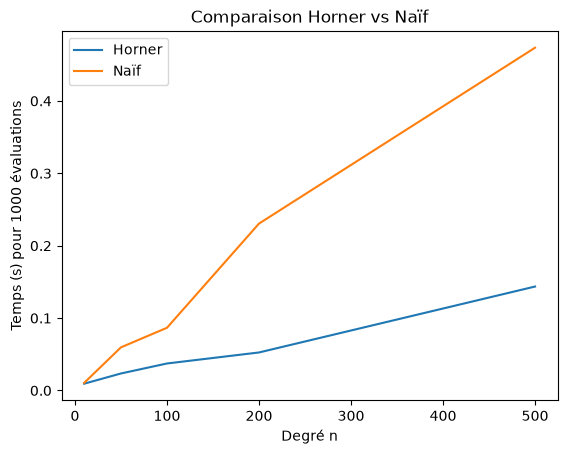

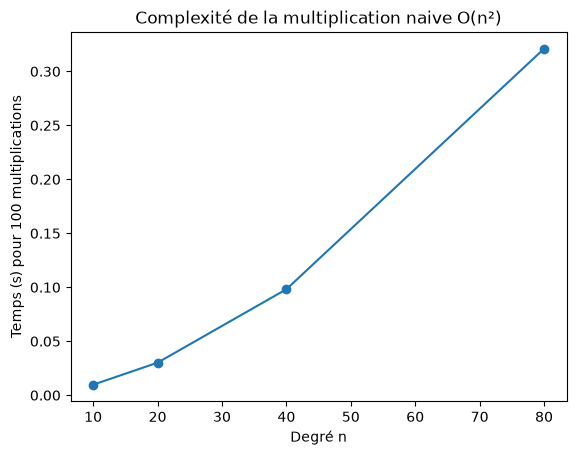

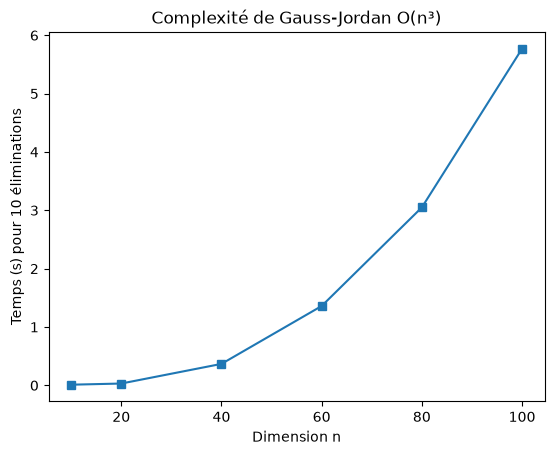

In [206]:
# 1. Évaluation de polynôme : Horner vs naïve
def eval_naive(P, x):
    res = 0
    for i, a in enumerate(P.coeffs):
        res += a * (x ** i)
    return res

# Polynôme de degré n avec coefficients aléatoires
n_vals = [10, 50, 100, 200, 500]
temps_horner = []
temps_naive = []
for n in n_vals:
    coeffs = np.random.randn(n+1).tolist()
    P = Polynome(coeffs)
    x = 2.3
    t_h = timeit.timeit(lambda: P.evaluer(x), number=1000)
    t_n = timeit.timeit(lambda: eval_naive(P, x), number=1000)
    temps_horner.append(t_h)
    temps_naive.append(t_n)

plt.plot(n_vals, temps_horner, label='Horner')
plt.plot(n_vals, temps_naive, label='Naïf')
plt.xlabel('Degré n')
plt.ylabel('Temps (s) pour 1000 évaluations')
plt.legend()
plt.title('Comparaison Horner vs Naïf')
plt.show()

# 2. Multiplication de polynômes
# On mesure le temps de multiplication pour différents degrés
n_vals = [10, 20, 40, 80]
temps_mul = []
for n in n_vals:
    coeffs1 = np.random.randn(n+1).tolist()
    coeffs2 = np.random.randn(n+1).tolist()
    P = Polynome(coeffs1)
    Q = Polynome(coeffs2)
    t_m = timeit.timeit(lambda: P * Q, number=100)
    temps_mul.append(t_m)
plt.figure()
plt.plot(n_vals, temps_mul, 'o-')
plt.xlabel('Degré n')
plt.ylabel('Temps (s) pour 100 multiplications')
plt.title('Complexité de la multiplication naive O(n²)')
plt.show()

# 3. Élimination de Gauss pour matrices aléatoires
dim = [10, 20, 40, 60, 80, 100]
temps_gauss = []
for n in dim:
    M = Matrice(np.random.randn(n, n).tolist())
    t_g = timeit.timeit(lambda: M.gauss_jordan(), number=10)
    temps_gauss.append(t_g)
plt.figure()
plt.plot(dim, temps_gauss, 's-')
plt.xlabel('Dimension n')
plt.ylabel('Temps (s) pour 10 éliminations')
plt.title('Complexité de Gauss-Jordan O(n³)')
plt.show()

EXERCICE 1 : CLASS COMPLEXE

In [207]:
class Complexe:
    def __init__(self, re, im=0):
        self.re = re
        self.im = im

    def __add__(self, other):
        return Complexe(self.re + other.re, self.im + other.im)

    def __mul__(self, other):
        return Complexe(self.re * other.re - self.im * other.im,
                        self.re * other.im + self.im * other.re)

    def conjugue(self):
        return Complexe(self.re, -self.im)

    def module(self):
        return math.sqrt(self.re**2 + self.im**2)

    def __str__(self):
        return f"{self.re} + {self.im}i"

# Test
z = Complexe(3, 4)
w = Complexe(1, -2)
print(f"z = {z}, w = {w}")
print(f"z + w = {z + w}")
print(f"z * w = {z * w}")
print(f"|z| = {z.module()}")
print(f"|z*w| = {(z*w).module()}")
print(f"|z|*|w| = {z.module() * w.module()}")
assert abs((z*w).module() - z.module() * w.module()) < 1e-9
print("Propriété |zw| = |z||w| vérifiée.")


z = 3 + 4i, w = 1 + -2i
z + w = 4 + 2i
z * w = 11 + -2i
|z| = 5.0
|z*w| = 11.180339887498949
|z|*|w| = 11.180339887498949
Propriété |zw| = |z||w| vérifiée.


EXERCICE 2 : METHODE DE LAGRANGE

In [208]:
def lagrange(xs, ys):
    """Retourne le polynôme d'interpolation de Lagrange."""
    n = len(xs)
    P = Polynome([0])
    for i in range(n):
        # Polynôme de base L_i
        Li = Polynome([1])
        for j in range(n):
            if i != j:
                # (X - xj) / (xi - xj)
                numer = Polynome([-xs[j], 1])   # X - xj
                denom = xs[i] - xs[j]
                Li = Li * numer * (1 / denom)
        P = P + Li * ys[i]
    return P

# Test avec (0,0), (1,1), (2,4) -> X²
xs = [0, 1, 2]
ys = [0, 1, 4]
L = lagrange(xs, ys)
print(f"Polynôme interpolateur : {L}")
print(f"Vérification : L(0)={L(0)}, L(1)={L(1)}, L(2)={L(2)}")


Polynôme interpolateur : X^2
Vérification : L(0)=0.0, L(1)=1.0, L(2)=4.0


EXERCICE 3 : METHODE DE VERIFICATION D'UN ANNEAU

In [194]:
def verifier_anneau(P, Q, R):
    ok = True
    # Commutativité de +
    if P + Q != Q + P:
        print("Erreur : P+Q != Q+P")
        ok = False
    # Associativité de +
    if (P + Q) + R != P + (Q + R):
        print("Erreur : (P+Q)+R != P+(Q+R)")
        ok = False
    # Associativité de *
    if (P * Q) * R != P * (Q * R):
        print("Erreur : (P*Q)*R != P*(Q*R)")
        ok = False
    # Distributivité
    if P * (Q + R) != P * Q + P * R:
        print("Erreur : P*(Q+R) != P*Q + P*R")
        ok = False
    if (P + Q) * R != P * R + Q * R:
        print("Erreur : (P+Q)*R != P*R + Q*R")
        ok = False
    # Commutativité de * (pour K[X])
    if P * Q != Q * P:
        print("Erreur : P*Q != Q*P")
        ok = False
    if ok:
        print("Tous les axiomes sont vérifiés.")
    return ok

# Test avec des polynômes aléatoires
P = Polynome([1, 2, 3])
Q = Polynome([-1, 0, 4])
R = Polynome([5, -1])
verifier_anneau(P, Q, R)

Tous les axiomes sont vérifiés.


True

EXERCICE 4 : MATRICE JACOBIENNE D'UN POLYNOME

In [195]:
def jacobi(self, b, tol=1e-8, max_iter=1000):
    assert self.m == self.n, "Matrice carrée requise"
    n = self.n
    x = [0.0] * n
    for _ in range(max_iter):
        x_new = [0.0] * n
        for i in range(n):
            s = 0.0
            for j in range(n):
                if j != i:
                    s += self.data[i][j] * x[j]
            x_new[i] = (b[i] - s) / self.data[i][i]
        # Vérification de convergence
        err = max(abs(x_new[i] - x[i]) for i in range(n))
        x = x_new
        if err < tol:
            return x
    return x

# On attache la méthode à la classe Matrice (pour éviter de réécrire)
Matrice.jacobi = jacobi

# Test
A = Matrice([[4, 1], [1, 3]])
b = [1, 2]
x = A.jacobi(b)
print("Solution Jacobi :", x)
B = Matrice.identite(n) * 10


Solution Jacobi : [0.09090909069766542, 0.636363634883658]


EXERCICE 5 : DECOMPOSITION EN LU D'UNE MATRICE

In [196]:
def matrice_decomposition_LU(self):
    """
    Décomposition A = LU sans pivot.
    Retourne (L, U) où L est triangulaire inférieure (diagonale = 1)
    et U est triangulaire supérieure.
    Complexité : O(n^3).
    """
    n = self.n
    # Initialisation : L = identité, U = copie de la matrice
    L = Matrice.identite(n)
    U = Matrice([row[:] for row in self.data])

    for k in range(n):
        # Si pivot nul, on ne peut pas poursuivre sans pivot
        if abs(U.data[k][k]) < 1e-12:
            raise ValueError("Pivot nul : décomposition LU sans pivot impossible")
        for i in range(k+1, n):
            facteur = U.data[i][k] / U.data[k][k]
            L.data[i][k] = facteur  # on stocke le multiplicateur dans L
            for j in range(k, n):
                U.data[i][j] -= facteur * U.data[k][j]
    return L, U

def substitution_avant(L, b):
    """Résout Ly = b, L triangulaire inférieure (diagonale = 1). O(n^2)."""
    n = len(b)
    y = [0.0] * n
    for i in range(n):
        somme = b[i]
        for j in range(i):
            somme -= L.data[i][j] * y[j]
        y[i] = somme  # car L[i][i] = 1
    return y

def substitution_arriere(U, b):
    """Résout Ux = b, U triangulaire supérieure. O(n^2)."""
    n = len(b)
    x = [0.0] * n
    for i in range(n-1, -1, -1):
        somme = b[i]
        for j in range(i+1, n):
            somme -= U.data[i][j] * x[j]
        x[i] = somme / U.data[i][i]
    return x

# Attacher les méthodes à la classe Matrice (si déjà définie)
Matrice.decomposition_LU = matrice_decomposition_LU
Matrice.substitution_avant = staticmethod(substitution_avant)
Matrice.substitution_arriere = staticmethod(substitution_arriere)

In [197]:
#test
A = Matrice([[2, 1, 1], [4, 3, 3], [8, 7, 9]])
L, U = A.decomposition_LU()

print("L =")
print(L)
print("\nU =")
print(U)

# Vérification : L * U doit redonner A
print("\nL * U =")
print(L * U)

# Vérification que A == L*U (approximativement)
reconstruite = L * U
erreur = max(abs(A.data[i][j] - reconstruite.data[i][j]) for i in range(A.n) for j in range(A.n))
print(f"\nErreur de reconstruction : {erreur:.2e}")

L =
| 1  0  0 |
| 2  1  0 |
| 4  3  1 |

U =
| 2  1  1 |
| 0  1  1 |
| 0  0  2 |

L * U =
None


AttributeError: 'NoneType' object has no attribute 'data'

In [ ]:
"""if isinstance(other, (int, float)):
        return Matrice([[other * x for x in lig] for lig in self.data])
        assert self.n == other.m, f"Dimensions : ({self.m},{self.n}) x ({other.m},{other.n})"
    # TODO : construire la matrice résultat case par case
    resultat=[]
    for i in range(len(self.m)):
        for j in range (len(other.n)):
            resultat.data[i][j]=sum(self.data[i][k]*other.data[k][j] for k in range (self.n) )
    return resultat"""
    if isinstance(other, (int, float)):
        return Matrice([[other * x for x in ligne] for ligne in self.data])
        assert self.n == other.m, "Dimensions incompatibles pour multiplication"
        resultat = Matrice.nulle(self.m, other.n)
        for i in range(self.m):
            for j in range(other.n):
                s = 0
                for k in range(self.n):
                    s += self.data[i][k] * other.data[k][j]
                resultat.data[i][j] = s
        return Matrice(resultat)

